In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv("test_output/expression_profiles/profile_qc/confusion_matrix.csv")
df = df.set_index("most probable cluster", drop=True)

In [3]:
df

,Adult eye,Anterior nervous system,Cardiovascular system,Central nervous system,Developing neurons,Enteric nervous system,Epidermis,Gland cells,Glia,Heme/chitin,Macrophage,Midgut,Motile cilia,Somatic musculature,Stem cells,autofluorescence,zero
most probable cluster,,,,,,,,,,,,,,,,,
Adult eye,0.9586,0.0033,0.0049,0.0035,0.0072,0.0040,0.0044,0.0143,0.0046,0.0103,0.0124,0.0069,0.0082,0.0005,0.0209,0.0,0.0001
Anterior nervous system,0.0014,0.8630,0.0043,0.0434,0.0363,0.0288,0.0042,0.0113,0.0056,0.0046,0.0036,0.0068,0.0155,0.0003,0.0079,0.0,0.0000
Cardiovascular system,0.0020,0.0039,0.6554,0.0046,0.0040,0.0021,0.0568,0.0182,0.0077,0.0514,0.0728,0.0551,0.0098,0.0227,0.0545,0.0,0.0000
Central nervous system,0.0015,0.0322,0.0014,0.6519,0.1272,0.0217,0.0029,0.0137,0.0014,0.0040,0.0003,0.0012,0.0709,0.0001,0.0095,0.0,0.0000
Developing neurons,0.0019,0.0249,0.0020,0.1454,0.6597,0.0137,0.0060,0.0180,0.0065,0.0128,0.0010,0.0017,0.0629,0.0001,0.0237,0.0,0.0000
Enteric nervous system,0.0008,0.0206,0.0027,0.0264,0.0197,0.8552,0.0024,0.0083,0.0028,0.0057,0.0028,0.0145,0.0216,0.0004,0.0098,0.0,0.0000
Epidermis,0.0010,0.0015,0.0338,0.0021,0.0065,0.0014,0.6017,0.0249,0.0068,0.0856,0.0436,0.0380,0.0138,0.0015,0.0458,0.0,0.0000
Gland cells,0.0046,0.0126,0.0171,0.0244,0.0285,0.0122,0.0292,0.6605,0.0250,0.0631,0.0318,0.0271,0.0356,0.0012,0.0540,0.0,0.0001
Glia,0.0023,0.0076,0.0109,0.0045,0.0094,0.0036,0.0115,0.0265,0.8873,0.0162,0.0114,0.0161,0.0063,0.0010,0.0168,0.0,0.0000


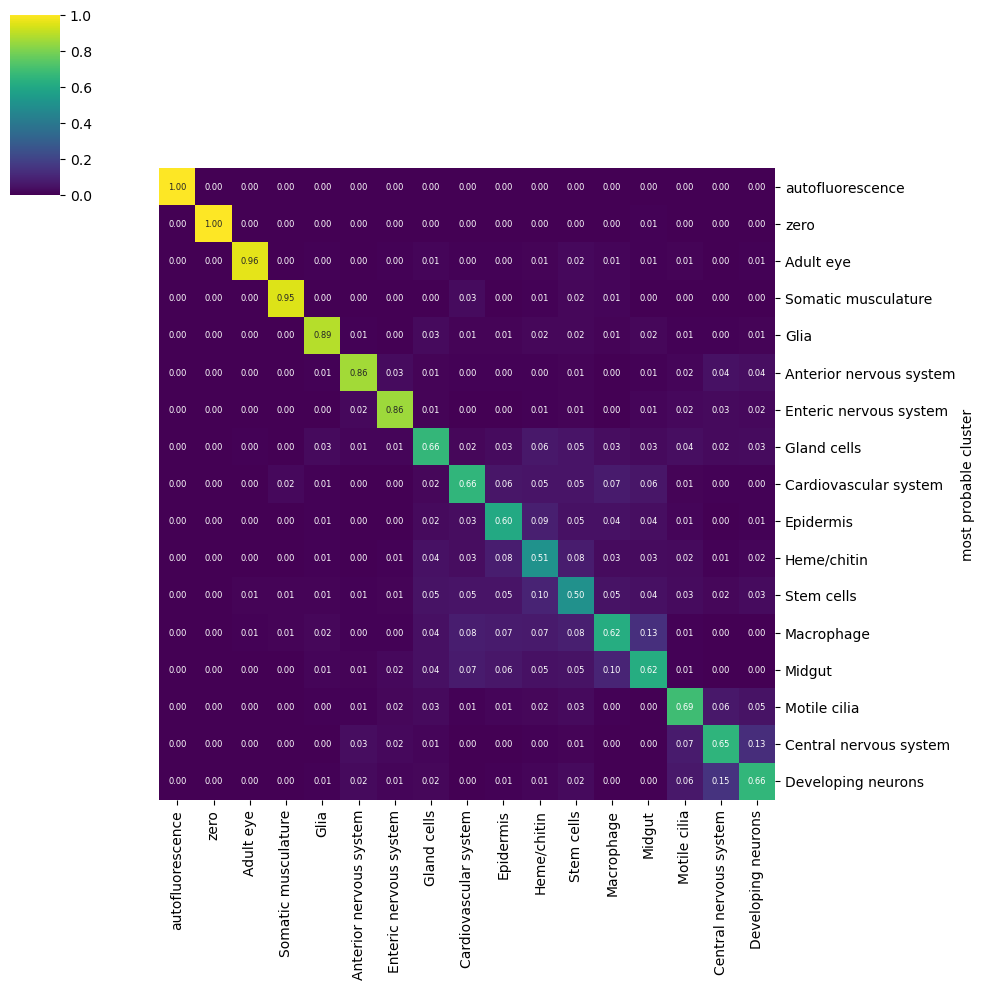

In [4]:
cg = sns.clustermap(df, cmap="viridis", annot=True, annot_kws={"fontsize":6}, fmt='.2f')
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.savefig("confusion_matrix_broad_types.png", dpi=300)

In [10]:
df = pd.read_csv("small_groups_output/expression_profiles/profile_qc/confusion_matrix.csv")
df = df.set_index("most probable cluster", drop=True)

In [11]:
df.head()

,autofluorescence,clade10sub10,clade10sub11,clade10sub13,clade10sub14,clade10sub15,clade10sub19,clade10sub20,clade10sub21,clade10sub22,...,nocladesub3,nocladesub30,nocladesub32,nocladesub33,nocladesub35,nocladesub4,nocladesub7,nocladesub8,nocladesub9,zero
most probable cluster,,,,,,,,,,,,,,,,,,,,,
autofluorescence,1.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000,0.0000,0.0
clade10sub10,0.0,0.6673,0.0088,0.0225,0.0352,0.0067,0.0189,0.0021,0.0018,0.0048,...,0.0004,0.0000,0.0006,0.0000,0.0,0.0000,0.0000,0.0001,0.0002,0.0
clade10sub11,0.0,0.0107,0.7111,0.0014,0.0304,0.0040,0.0102,0.0008,0.0049,0.0005,...,0.0018,0.0001,0.0007,0.0001,0.0,0.0000,0.0003,0.0005,0.0002,0.0
clade10sub13,0.0,0.0222,0.0016,0.7629,0.0091,0.0188,0.0051,0.0174,0.0141,0.0092,...,0.0004,0.0000,0.0010,0.0000,0.0,0.0000,0.0003,0.0004,0.0001,0.0
clade10sub14,0.0,0.0252,0.0214,0.0073,0.6748,0.0123,0.0077,0.0005,0.0023,0.0011,...,0.0007,0.0002,0.0004,0.0000,0.0,0.0001,0.0000,0.0003,0.0000,0.0


In [12]:
df.loc["clade10sub9", "clade10sub9"]

np.float64(0.6035)

<BarContainer object of 276 artists>

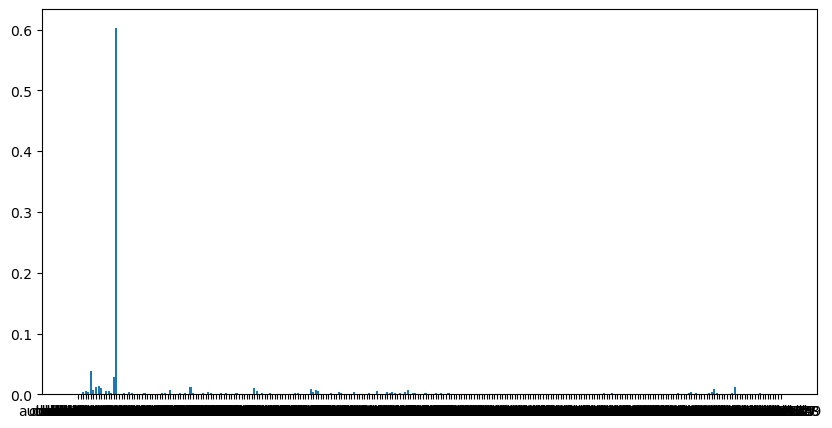

In [15]:
plt.figure(figsize=(10,5))
plt.bar(df["clade10sub9"].index, df["clade10sub9"])

In [7]:
import scipy.cluster.hierarchy as sch

def cluster_corr(corr_array, inplace=False):
    """
    Rearranges the correlation matrix, corr_array, so that groups of highly 
    correlated variables are next to eachother 
    
    Parameters
    ----------
    corr_array : pandas.DataFrame or numpy.ndarray
        a NxN correlation matrix 
        
    Returns
    -------
    pandas.DataFrame or numpy.ndarray
        a NxN correlation matrix with the columns and rows rearranged
    """
    pairwise_distances = np.array(corr_array)
    linkage = sch.linkage(pairwise_distances, method='complete')
    cluster_distance_threshold = pairwise_distances.max()/2
    idx_to_cluster_array = sch.fcluster(linkage, cluster_distance_threshold, 
                                        criterion='distance')
    idx = np.argsort(idx_to_cluster_array)
    
    if not inplace:
        corr_array = corr_array.copy()
    
    if isinstance(corr_array, pd.DataFrame):
        return corr_array.iloc[idx, :].T.iloc[idx, :]
    return corr_array[idx, :][:, idx]

In [8]:
cluster_corr(df)

most probable cluster,clade11sub1subsub10,clade11sub60,clade12sub64,clade9sub14,clade11sub25subsub6,clade11sub41subsub1,clade11sub18subsub2,nocladesub19,clade2sub8,clade2sub9,...,clade11sub57,clade11sub20subsub5,clade11sub27subsub8,clade11sub64,clade11sub54subsub1,clade11sub45subsub1,clade11sub6subsub11,clade11sub13subsub6,autofluorescence,zero
clade11sub1subsub10,0.9005,0.0010,0.0017,0.0003,0.0004,0.0004,0.0000,0.0000,0.0000,0.0001,...,0.0000,0.0002,0.0000,0.0001,0.0006,0.0000,0.0004,0.0000,0.0,0.0000
clade11sub60,0.0024,0.9022,0.0002,0.0002,0.0003,0.0004,0.0001,0.0002,0.0001,0.0000,...,0.0000,0.0000,0.0001,0.0013,0.0000,0.0007,0.0000,0.0000,0.0,0.0000
clade12sub64,0.0016,0.0000,0.9005,0.0035,0.0002,0.0003,0.0000,0.0002,0.0000,0.0000,...,0.0000,0.0002,0.0000,0.0001,0.0000,0.0000,0.0000,0.0001,0.0,0.0000
clade9sub14,0.0003,0.0004,0.0047,0.9007,0.0001,0.0003,0.0002,0.0007,0.0004,0.0001,...,0.0000,0.0003,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000
clade11sub25subsub6,0.0007,0.0002,0.0001,0.0000,0.8768,0.0045,0.0003,0.0001,0.0001,0.0000,...,0.0000,0.0000,0.0002,0.0000,0.0001,0.0002,0.0008,0.0000,0.0,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
clade11sub45subsub1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0003,0.0001,0.0000,0.0000,...,0.0001,0.0000,0.0000,0.0000,0.0000,0.9829,0.0000,0.0000,0.0,0.0000
clade11sub6subsub11,0.0004,0.0000,0.0000,0.0000,0.0003,0.0000,0.0000,0.0000,0.0002,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0009,0.0000,0.9870,0.0000,0.0,0.0000
clade11sub13subsub6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.9880,0.0,0.0000
autofluorescence,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,0.0000


In [9]:
clustered_df = cluster_corr(df)

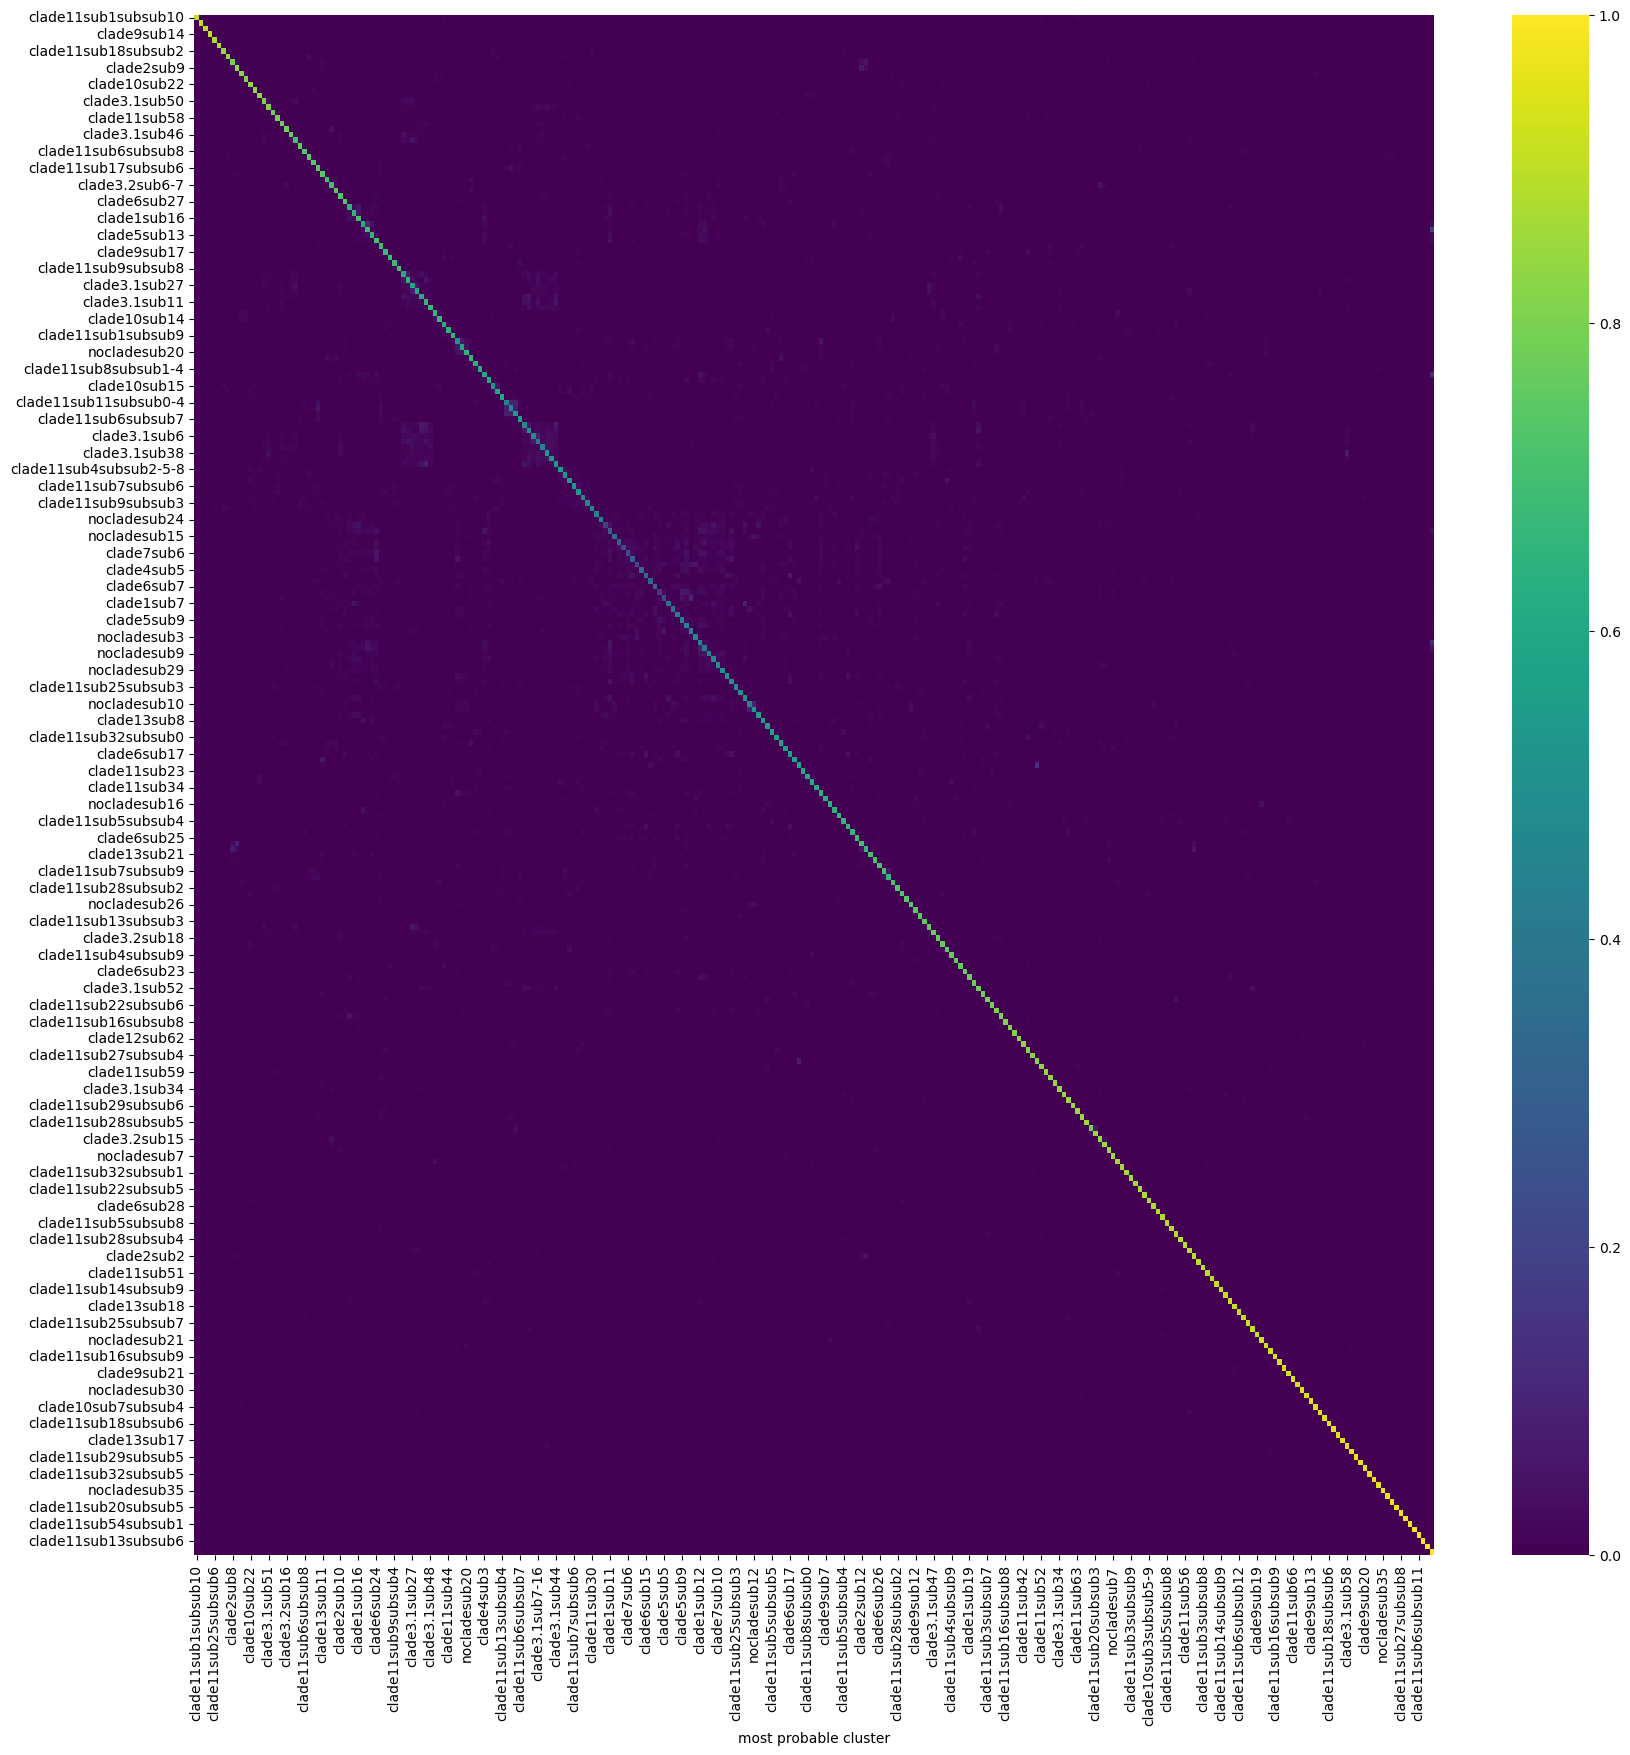

In [10]:
plt.figure(figsize=(20, 20))
sns.heatmap(clustered_df, cmap="viridis")
plt.savefig("confusion_matrix_small_groups.png", dpi=300)

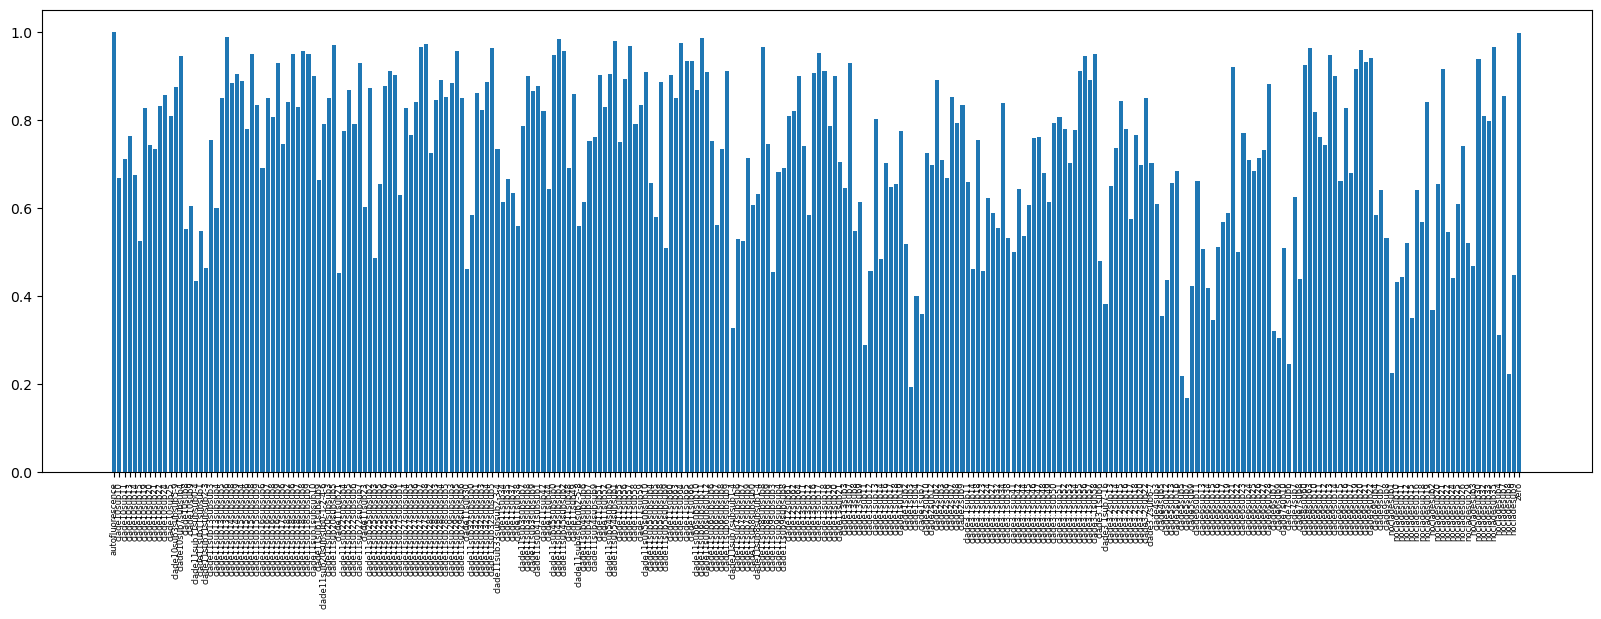

In [ ]:



fig, ax = plt.subplots(figsize=(20, 6))
ax.bar(df.columns, self_assignment)
ax.tick_params("x", rotation=90, labelsize=6)

In [86]:
self_assignment = [clustered_df.loc[cluster, cluster] for cluster in clustered_df.columns]
clustered_df_ambig = clustered_df.loc[np.array(self_assignment) < 0.6, np.array(self_assignment) < 0.6]

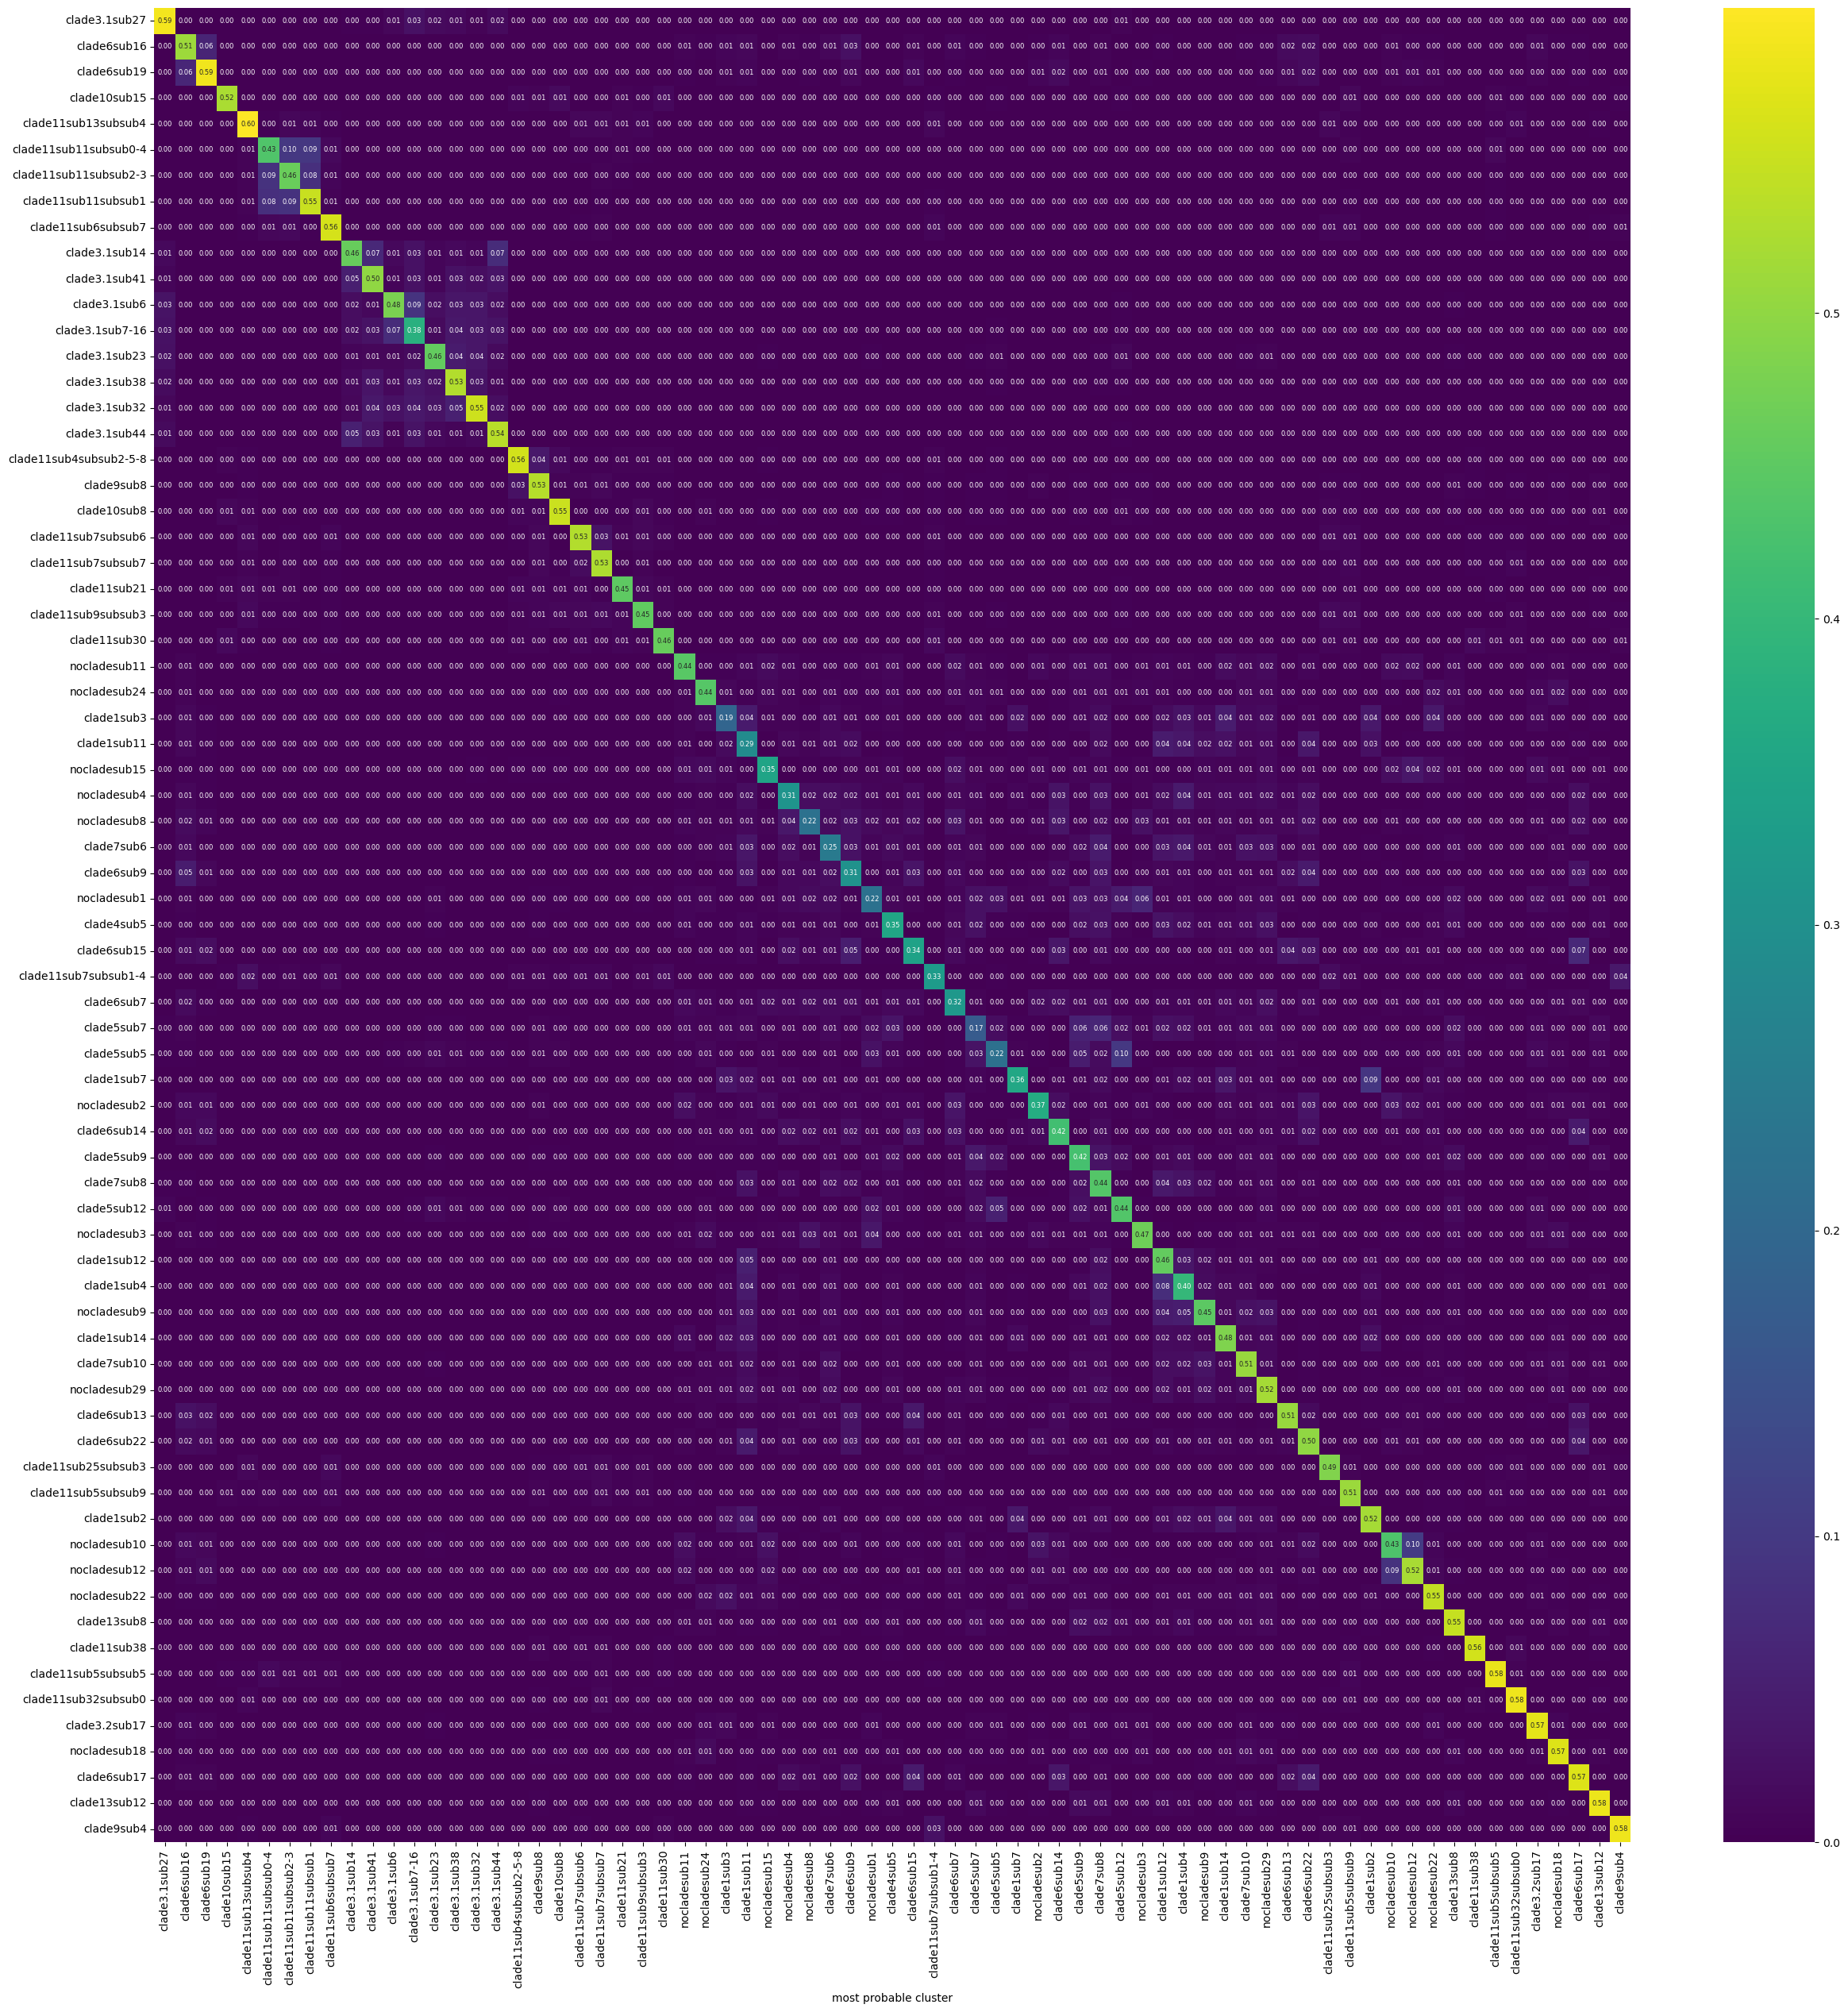

In [87]:
plt.figure(figsize=(30, 30))
sns.heatmap(clustered_df_ambig, cmap="viridis", annot=True, annot_kws={"fontsize":6}, fmt='.2f')
plt.savefig("confusion_matrix_small_groups_ambiguous.png", dpi=300)

In [3]:
df = pd.read_csv("small_groups_output/cluster_prob/cluster_probability.tsv", sep="\t")
df["label_id"] = df["label_id"].astype(int)
df = df.set_index("label_id", drop=True)
df = df.drop(labels=["most probable cluster"], axis=1)

In [4]:
df.iloc[0:100, :]

,clade3.2sub6-7,clade1sub4,clade10sub20,clade11sub6subsub10,clade1sub3,clade11sub11subsub0-4,clade11sub21,clade11sub35,clade5sub9,clade3.1sub7-16,...,clade11sub27subsub6,clade11sub15subsub9,clade11sub6subsub11,clade13sub20,clade11sub65,clade11sub45subsub2,clade10sub7subsub4,clade11sub1subsub10,zero,autofluorescence
label_id,,,,,,,,,,,,,,,,,,,,,
1,5.426956e-30,1.801896e-50,4.888863e-25,1.940912e-53,2.360897e-22,8.049824e-52,1.595054e-27,1.513102e-43,1.634277e-37,1.354980e-28,...,8.000846e-62,3.961832e-67,6.297594e-82,1.388989e-64,9.622465e-59,5.793596e-64,1.317467e-53,1.782449e-62,7.650868e-97,0.0
2,6.274823e-33,6.918811e-52,4.776493e-24,5.176593e-51,1.070012e-28,6.799251e-61,4.395646e-23,1.695077e-36,8.611096e-34,5.071634e-31,...,5.698117e-58,1.345089e-52,2.158421e-66,1.074600e-58,2.169829e-47,3.419972e-73,6.241827e-54,7.418147e-62,1.131813e-98,0.0
3,3.749887e-27,8.559227e-62,4.004945e-30,1.875636e-58,6.294452e-30,4.158747e-46,3.442236e-23,4.649206e-36,1.673067e-36,1.875762e-26,...,3.820725e-67,5.405913e-70,6.445448e-87,1.231084e-71,1.901992e-64,3.302311e-89,3.552450e-61,1.872953e-75,8.186834e-132,0.0
4,5.024281e-20,1.661937e-28,5.676685e-17,1.830578e-28,4.885791e-16,3.543685e-31,6.088470e-15,1.687325e-20,8.137230e-22,2.555705e-19,...,1.782613e-32,5.693950e-34,1.066634e-44,8.051807e-35,8.228520e-35,3.829308e-32,2.036634e-34,6.639567e-36,1.201534e-54,0.0
5,3.894818e-54,3.431175e-106,6.099275e-27,1.230160e-108,3.203558e-58,4.202738e-69,4.653235e-20,5.150542e-57,2.230167e-55,4.420092e-55,...,1.479811e-113,1.793826e-128,3.092463e-146,5.902508e-111,1.532729e-111,1.629919e-149,9.732240e-78,5.073044e-131,0.000000e+00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,1.118679e-30,1.082653e-34,2.811546e-16,1.939480e-33,6.425938e-26,1.728351e-12,3.092290e-01,6.049095e-09,6.063529e-19,5.875136e-33,...,2.997629e-30,1.704402e-26,4.985898e-41,5.438166e-41,1.452293e-23,1.438342e-37,1.815028e-29,5.743267e-23,3.136177e-99,0.0
104,4.745530e-33,3.354826e-49,9.416308e-17,1.642709e-30,1.472812e-28,7.283675e-21,9.998727e-01,1.050316e-11,3.238224e-23,1.485363e-34,...,1.210225e-40,2.142902e-22,2.047895e-57,2.968598e-55,1.724928e-46,2.550375e-40,3.863552e-33,1.432955e-30,2.237948e-140,0.0
105,4.976046e-34,6.429224e-31,6.080412e-16,1.040248e-24,5.434202e-23,4.440867e-07,9.915306e-01,8.307278e-18,1.169496e-20,3.352814e-25,...,4.132813e-24,2.224190e-27,1.099157e-29,8.835086e-24,2.128177e-33,5.315093e-46,1.836071e-16,9.696683e-31,2.499298e-72,0.0


In [9]:
df["clade10sub9"]

label_id
1        5.321224e-14
2        1.566366e-18
3        7.764223e-14
4        3.151888e-09
5        7.666577e-01
             ...     
11467    5.250233e-21
11468    1.013992e-20
11470    2.730676e-16
11471    1.908809e-20
11486    3.938438e-18
Name: clade10sub9, Length: 11382, dtype: float64

/home/buglakov/miniconda3/envs/cluster_map_env/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/buglakov/miniconda3/envs/cluster_map_env/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


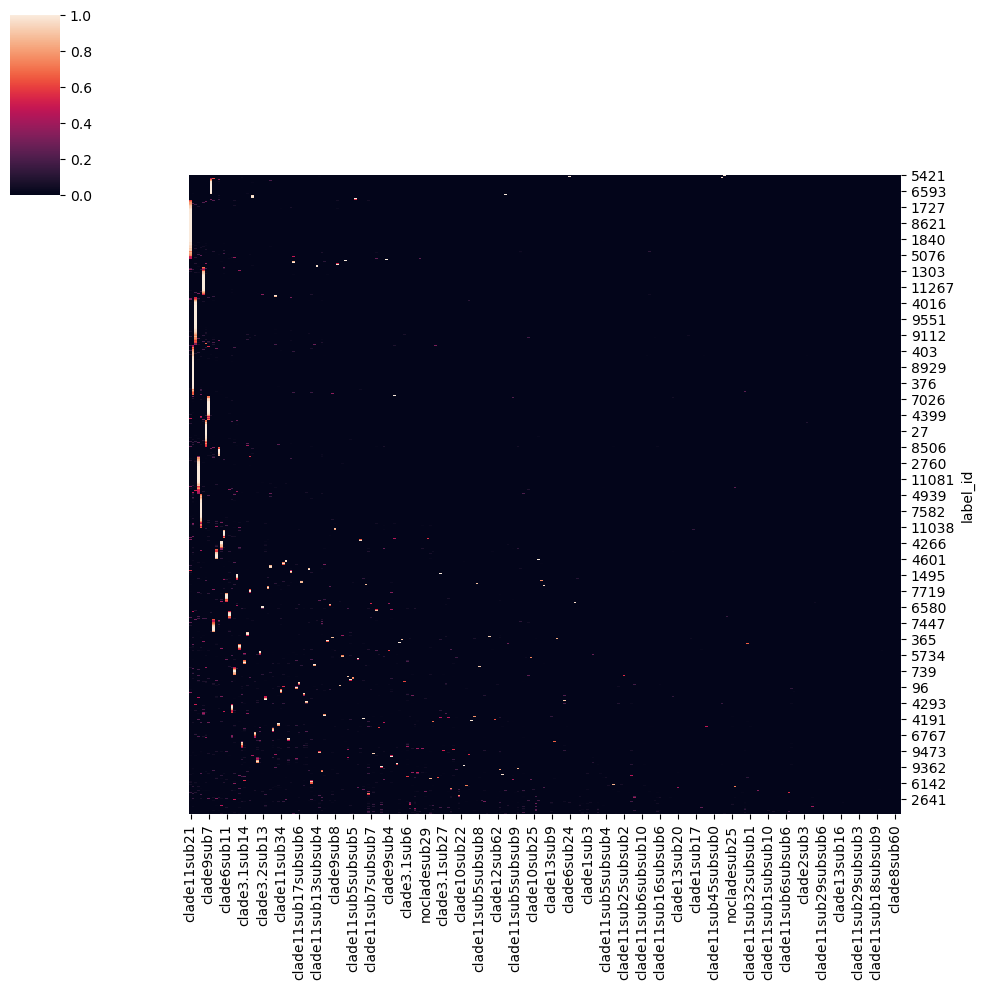

In [17]:
cg = sns.clustermap(df, col_cluster=True)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)

In [1]:
df.head()

NameError: name 'df' is not defined